# Pivot Sensitivity Analysis

Algorithm implementations: [`psc_logistic.py`](psc_logistic.py) · [`psc_lotka_volterra.py`](psc_lotka_volterra.py)

**Section 1** — Logistic pivot sweep  
**Section 2** — Lotka-Volterra pivot grid

---
## Setup

In [1]:
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path("tmp") / "matplotlib"))

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator
from scipy.integrate import solve_ivp

from psc_logistic import build_carleman_matrix_scalar, ps_coeffs
from psc_lotka_volterra import F_matrices, build_carleman_matrix, lifted_ic, lv_rhs

quick = False
save_figures = False
figure_dir = Path("figures")
error_cap = 1e2
failure_threshold = 1e2

plt.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif", "Times New Roman"],
    "axes.spines.top": True,
    "axes.spines.right": True,
    "axes.spines.bottom": True,
    "axes.spines.left": True,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.size": 24,
})
pal8 = sns.color_palette("colorblind", n_colors=8)

In [2]:
def grid_with_required(start, stop, num, required):
    values = [*np.linspace(start, stop, num), *required]
    return np.array(sorted({round(float(value), 12) for value in values}))


def lifted_rhs(A, b):
    def rhs(_t, y):
        with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
            return A @ y + b
    return rhs


def logistic_reference(t_eval, r, x0):
    exp_rt = np.exp(r * t_eval)
    return (x0 * exp_rt) / (1.0 + x0 * (exp_rt - 1.0))


def logistic_run(pivot, N, *, r, x0, T, n_eval):
    t_eval = np.linspace(0.0, T, n_eval)
    x_exact = logistic_reference(t_eval, r, x0)
    F0, F1, F2 = ps_coeffs(r, pivot)
    u0 = x0 - pivot
    A, b = build_carleman_matrix_scalar(F0, F1, F2, N)
    y0 = np.array([u0**j for j in range(1, N + 1)])
    sol = solve_ivp(lifted_rhs(A, b), (0.0, T), y0,
                    t_eval=t_eval, method="RK45", rtol=1e-7, atol=1e-10)
    if sol.success:
        trajectory = sol.y[0] + pivot
        errors = np.abs(trajectory - x_exact)
        finite = bool(np.all(np.isfinite(trajectory)) and np.all(np.isfinite(errors)))
        max_error = float(np.max(errors)) if finite else np.nan
        final_error = float(errors[-1]) if finite else np.nan
        failed = (not finite) or max_error > failure_threshold
    else:
        max_error = np.nan
        final_error = np.nan
        failed = True
    return {"pivot": pivot, "N": N, "max_error": max_error,
            "final_error": final_error, "failed": failed}


def lotka_reference(t_eval, eta, gamma, x0):
    sol = solve_ivp(lambda t, x: lv_rhs(t, x, eta, gamma),
                    (float(t_eval[0]), float(t_eval[-1])), x0,
                    t_eval=t_eval, method="RK45", rtol=1e-12, atol=1e-12)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.y


def lotka_run(pivot, N, *, eta, gamma, x0, t_eval, reference):
    s = np.asarray(pivot, dtype=float)
    F0, F1, F2 = F_matrices(eta, gamma, s)
    A_N, b_N = build_carleman_matrix(F0, F1, F2, N)
    Y0 = lifted_ic(x0 - s, N)
    sol = solve_ivp(lifted_rhs(A_N, b_N),
                    (float(t_eval[0]), float(t_eval[-1])), Y0,
                    t_eval=t_eval, method="RK45", rtol=1e-9, atol=1e-12)
    if sol.success:
        trajectory = sol.y[:2, :] + s[:, None]
        errors = np.linalg.norm(trajectory - reference, axis=0)
        finite = bool(np.all(np.isfinite(trajectory)) and np.all(np.isfinite(errors)))
        max_error = float(np.max(errors)) if finite else np.nan
        final_error = float(errors[-1]) if finite else np.nan
        failed = (not finite) or max_error > failure_threshold
    else:
        max_error = np.nan
        final_error = np.nan
        failed = True
    return {"pivot_x1": float(s[0]), "pivot_x2": float(s[1]), "N": N,
            "max_error": max_error, "final_error": final_error, "failed": failed}

---
## Section 1 · Logistic Model

In [3]:
logistic_points = 21 if quick else 161
logistic_n_eval = 301 if quick else 2001
logistic_pivots = grid_with_required(-0.5, 1.5, logistic_points, [0.0, 0.5, 1.2])

logistic_rows = []
for N in [4, 8]:
    for pivot in logistic_pivots:
        logistic_rows.append(logistic_run(float(pivot), N, r=1.0, x0=0.5,
                                          T=10.0, n_eval=logistic_n_eval))

len(logistic_rows)

322

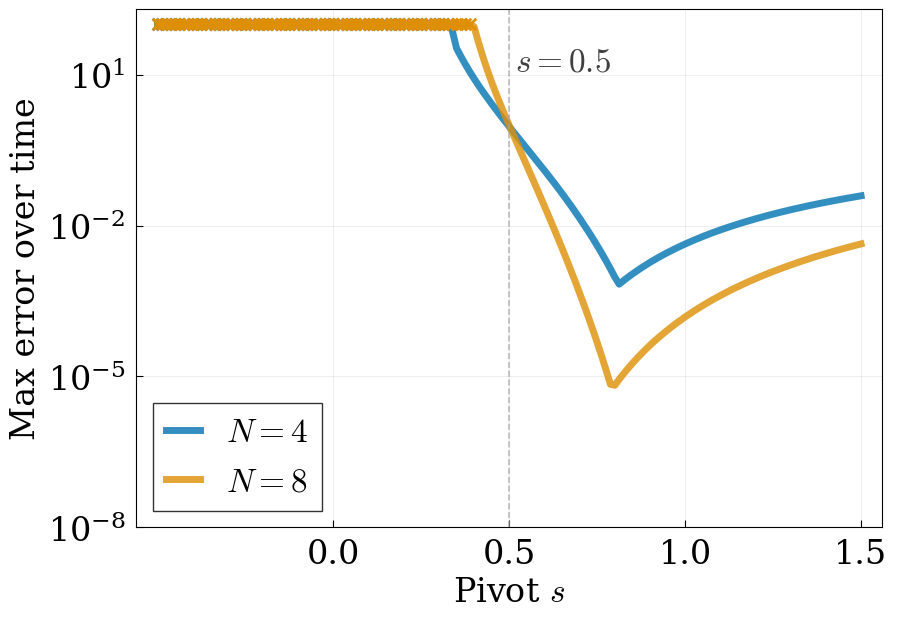

In [4]:
FS = 24
LW = 5.0
colors = {4: pal8[0], 8: pal8[1]}

fig, ax = plt.subplots(1, 1, figsize=(9.5, 7.0), constrained_layout=False)
for N in sorted({row["N"] for row in logistic_rows}):
    subset = [row for row in logistic_rows if row["N"] == N]
    pivots = np.array([row["pivot"] for row in subset])
    max_err = np.array([row["max_error"] for row in subset])
    failed = np.array([row["failed"] for row in subset])
    order = np.argsort(pivots)
    clipped = np.clip(max_err, 1e-16, error_cap)
    line = ax.semilogy(pivots[order], clipped[order], "-",
                       color=colors.get(N, pal8[N % len(pal8)]), lw=LW,
                       alpha=0.8, label=fr"$N={N}$")[0]
    if np.any(failed):
        ax.scatter(pivots[failed], np.full(np.sum(failed), error_cap),
                   marker="x", color=line.get_color(), s=70,
                   linewidths=2.0, zorder=4)

ax.axvline(0.5, color="0.65", linewidth=1.2, linestyle="--", alpha=0.75)
ax.text(0.515, 0.93, r"$s=0.5$", transform=ax.get_xaxis_transform(),
        ha="left", va="top", fontsize=FS, color="0.25")
ax.set_xlabel(r"Pivot $s$", fontsize=FS)
ax.set_ylabel("Max error over time", fontsize=FS)
ax.set_xlim(-0.56, 1.56)
ax.set_ylim(1e-8, error_cap * 2.0)
ax.set_xticks([0.0, 0.5, 1.0, 1.5])
ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax.grid(True, alpha=0.25, lw=0.6)
ax.legend(frameon=True, fancybox=False, edgecolor="black", fontsize=FS,
          loc="lower left", handlelength=1)
ax.tick_params(which="both", direction="in", top=False, right=False,
               length=5, labelsize=FS, pad=8)

fig.subplots_adjust(left=0.18, right=0.965, bottom=0.20, top=0.94)
if save_figures:
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_dir / "logistic_pivot_sensitivity.pdf", format="pdf", bbox_inches="tight")
plt.show()

---
## Section 2 · Lotka-Volterra Model

In [5]:
lotka_points = 7 if quick else 21
lotka_n_eval = 201 if quick else 800
eta, gamma = 1.0, 0.475
x0_lv = np.array([0.5, 0.5])
t_eval_lv = np.linspace(0.0, 2.0, lotka_n_eval)
reference_lv = lotka_reference(t_eval_lv, eta, gamma, x0_lv)

s1_values = grid_with_required(0.0, 1.2, lotka_points, [0.0, 0.5, 0.7])
s2_values = grid_with_required(0.0, 1.0, lotka_points, [0.0, 0.3, 0.5])

lotka_rows = []
for N in [4, 8]:
    for s1 in s1_values:
        for s2 in s2_values:
            lotka_rows.append(lotka_run((float(s1), float(s2)), N,
                                        eta=eta, gamma=gamma, x0=x0_lv,
                                        t_eval=t_eval_lv, reference=reference_lv))

len(lotka_rows)

966

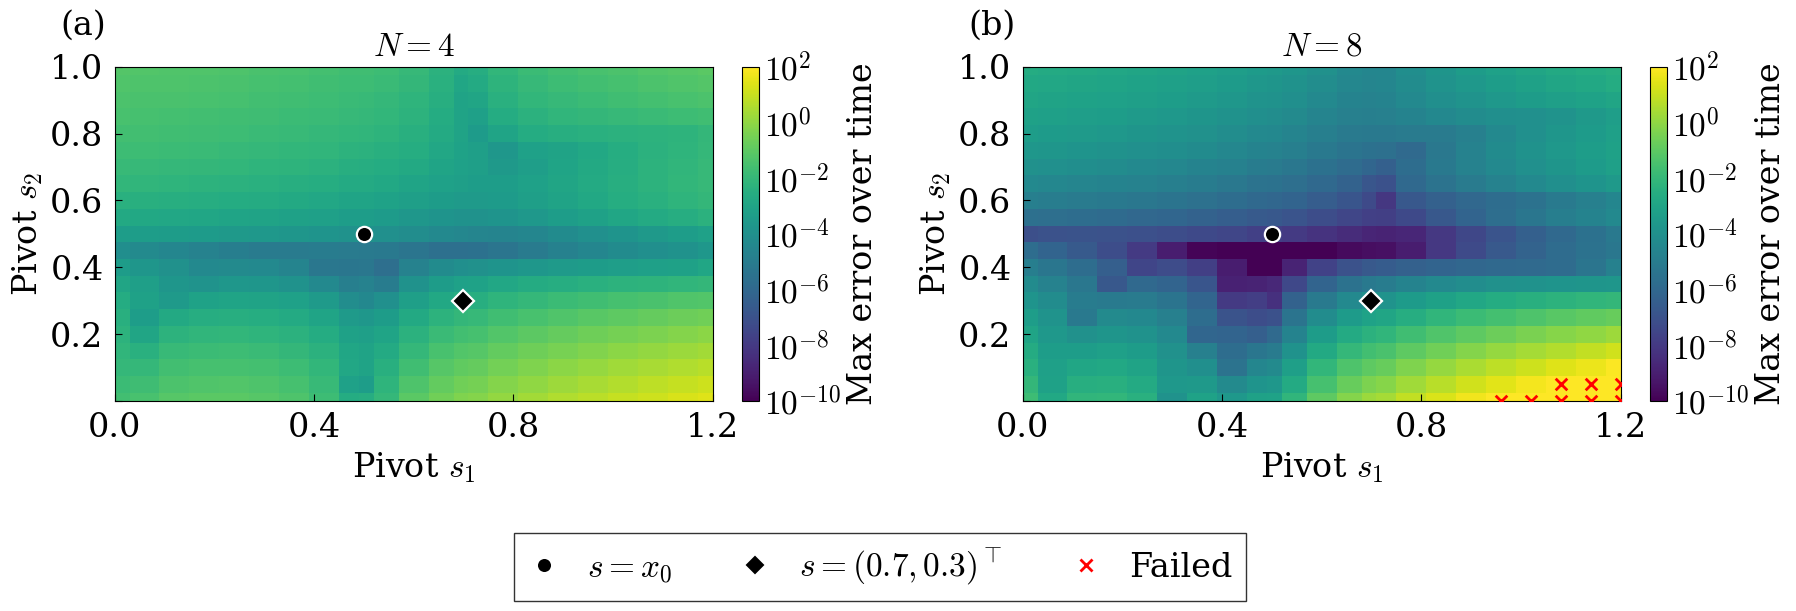

In [6]:
def cell_edges(values):
    centers = np.asarray(values, dtype=float)
    if len(centers) == 1:
        return np.array([centers[0] - 0.5, centers[0] + 0.5])
    midpoints = 0.5 * (centers[:-1] + centers[1:])
    first = centers[0] - (midpoints[0] - centers[0])
    last = centers[-1] + (centers[-1] - midpoints[-1])
    return np.concatenate([[first], midpoints, [last]])

FS = 24
Ns = sorted({row["N"] for row in lotka_rows})
fig, axes = plt.subplots(1, len(Ns), figsize=(18, 7.6), constrained_layout=False)
if len(Ns) == 1:
    axes = [axes]

for ax, N in zip(axes, Ns):
    subset = [row for row in lotka_rows if row["N"] == N]
    xvals = sorted({row["pivot_x1"] for row in subset})
    yvals = sorted({row["pivot_x2"] for row in subset})
    grid = np.full((len(yvals), len(xvals)), np.nan)
    x_index = {x: i for i, x in enumerate(xvals)}
    y_index = {y: i for i, y in enumerate(yvals)}
    for row in subset:
        grid[y_index[row["pivot_x2"]], x_index[row["pivot_x1"]]] = row["max_error"]

    image = ax.pcolormesh(cell_edges(xvals), cell_edges(yvals),
                          np.log10(np.clip(grid, 1e-16, error_cap)),
                          shading="auto", cmap="viridis", vmin=-10.0,
                          vmax=np.log10(error_cap))
    failed_rows = [row for row in subset if row["failed"]]
    if failed_rows:
        ax.scatter([row["pivot_x1"] for row in failed_rows],
                   [row["pivot_x2"] for row in failed_rows], marker="x",
                   color="red", s=70, linewidths=2.0, zorder=4)
    ax.plot(0.5, 0.5, marker="o", color="black", markeredgecolor="white",
            markeredgewidth=1.6, markersize=11, linestyle="None", zorder=5)
    ax.plot(0.7, 0.3, marker="D", color="black", markeredgecolor="white",
            markeredgewidth=1.6, markersize=11, linestyle="None", zorder=5)

    ax.set_title(fr"$N={N}$", fontsize=FS, pad=8)
    ax.set_xlabel(r"Pivot $s_1$", fontsize=FS)
    ax.set_ylabel(r"Pivot $s_2$", fontsize=FS)
    ax.set_xlim(0.0, 1.2)
    ax.set_ylim(0.0, 1.0)
    ax.set_xticks([0.0, 0.4, 0.8, 1.2])
    ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(["", "0.2", "0.4", "0.6", "0.8", "1.0"])
    ax.tick_params(which="both", direction="in", top=False, right=False,
                   length=5, labelsize=FS, pad=8)
    colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.045)
    colorbar.set_label("Max error over time", fontsize=FS)
    colorbar.set_ticks([-10, -8, -6, -4, -2, 0, 2])
    colorbar.set_ticklabels([r"$10^{-10}$", r"$10^{-8}$", r"$10^{-6}$",
                             r"$10^{-4}$", r"$10^{-2}$", r"$10^{0}$",
                             r"$10^{2}$"])
    colorbar.ax.tick_params(labelsize=FS, length=0)

axes[0].text(-0.09, 1.17, r"(a)", transform=axes[0].transAxes,
             ha="left", va="top", fontsize=FS, color="black")
axes[1].text(-0.09, 1.17, r"(b)", transform=axes[1].transAxes,
             ha="left", va="top", fontsize=FS, color="black")

legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="black",
           markeredgecolor="white", markeredgewidth=1.6, markersize=11,
           label=r"$s=x_0$"),
    Line2D([0], [0], marker="D", color="none", markerfacecolor="black",
           markeredgecolor="white", markeredgewidth=1.6, markersize=11,
           label=r"$s=(0.7,0.3)^\top$"),
    Line2D([0], [0], marker="x", color="red", linestyle="None",
           markersize=9, markeredgewidth=2.0, label="Failed"),
]
fig.legend(handles=legend_handles, frameon=True, fancybox=False,
           edgecolor="black", fontsize=FS, loc="lower center",
           bbox_to_anchor=(0.5, 0.055), ncol=3, handlelength=1)

fig.subplots_adjust(left=0.075, right=0.945, bottom=0.34, top=0.78, wspace=0.38)
if save_figures:
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_dir / "lotka_volterra_pivot_sensitivity.pdf", format="pdf", bbox_inches="tight")
plt.show()